<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/23bds0308.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

23BDS0308
Hierarchical and K-Means Clustering

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
# Load the dataset and check missing values
df = pd.read_csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv")
print(df.shape)
df.isna().sum()

(7430, 14)


,0
rownames,0
id,0
read12,0
math12,0
female,0
asian,0
hispan,0
black,0
motheduc,0
fatheduc,0


In [ ]:
# Select and standardize the numeric variables
cols = ["read12", "math12", "motheduc", "fatheduc", "lfaminc"]
X = StandardScaler().fit_transform(df[cols])

In [ ]:
# Hierarchical: sample 300 students and apply Ward's linkage
sample = X[np.random.default_rng(123).choice(len(X), 300, replace=False)]
Z = linkage(sample, method="ward", metric="euclidean")

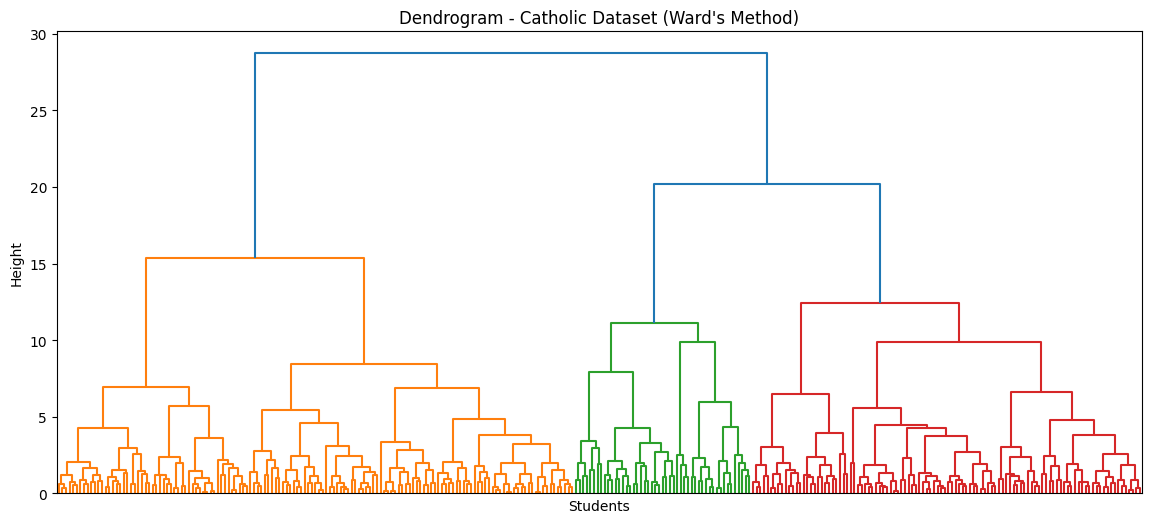

In [ ]:
# Hierarchical: dendrogram
plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram - Catholic Dataset (Ward's Method)")
plt.xlabel("Students")
plt.ylabel("Height")
plt.show()

In [ ]:
# Hierarchical: cut the tree into 3 clusters
clusters_hc = fcluster(Z, t=3, criterion="maxclust")
pd.Series(clusters_hc).value_counts().sort_index()

,count
1,143
2,49
3,108


In [ ]:
# Catholic HS distribution
df["cathhs"].value_counts()

,count
cathhs,
0,6978
1,452


In [ ]:
# K-Means with k = 2
km2 = KMeans(n_clusters=2, n_init=25, random_state=123).fit(X)
total_ss = ((X - X.mean(axis=0)) ** 2).sum()
print("Cluster sizes:", np.bincount(km2.labels_))
print(f"between_SS / total_SS = {1 - km2.inertia_ / total_ss:.1%}")
pd.DataFrame(km2.cluster_centers_, columns=cols).round(4)

Cluster sizes: [3594 3836]
between_SS / total_SS = 34.2%


,read12,math12,motheduc,fatheduc,lfaminc
0,-0.6782,-0.7131,-0.5339,-0.5849,-0.4701
1,0.6375,0.6703,0.5018,0.5498,0.4419


[37150.   24462.82 20699.75 17642.04 16230.91 15054.5  14066.56 13369.47
 12727.82 12106.48]


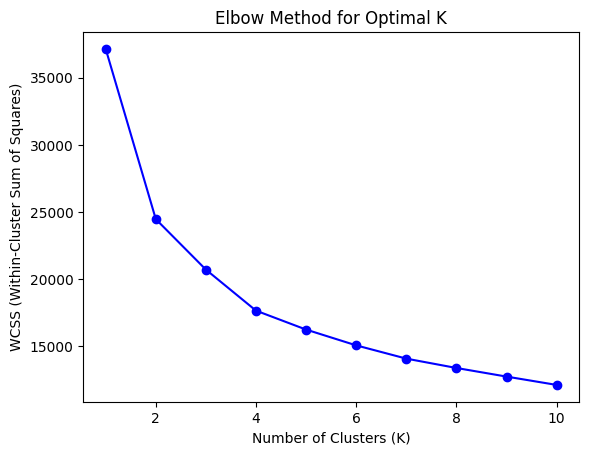

In [ ]:
# Elbow method to choose k
wcss = [KMeans(n_clusters=k, n_init=25, random_state=123).fit(X).inertia_ for k in range(1, 11)]
print(np.round(wcss, 2))
plt.plot(range(1, 11), wcss, "bo-")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.show()

In [ ]:
# Final K-Means with k = 3
km3 = KMeans(n_clusters=3, n_init=25, random_state=123).fit(X)
df["cluster"] = km3.labels_ + 1
print("Cluster sizes:", df["cluster"].value_counts().sort_index().tolist())
print(f"between_SS / total_SS = {1 - km3.inertia_ / total_ss:.1%}")
pd.DataFrame(km3.cluster_centers_, columns=cols, index=[1, 2, 3]).round(4)

Cluster sizes: [2493, 2036, 2901]
between_SS / total_SS = 44.3%


,read12,math12,motheduc,fatheduc,lfaminc
1,-1.0399,-1.0107,-0.5423,-0.6025,-0.5669
2,0.6445,0.7628,0.9871,1.0945,0.7279
3,0.4421,0.3339,-0.2274,-0.2510,-0.0238


In [ ]:
# Cluster profiles in original units
df.groupby("cluster")[cols].mean().round(2)

,read12,math12,motheduc,fatheduc,lfaminc
cluster,,,,,
1,41.99,42.57,12.27,12.31,9.90
2,57.83,59.35,15.34,16.16,10.93
3,55.93,55.29,12.90,13.11,10.34
